# Helmet Detection Using YOLOv8

This project focuses on detecting helmet usage using computer vision.  
Two approaches are used:

- Classification model to predict helmet vs no helmet
- Detection model to locate helmets in images

The goal of this project is to build a reliable system that can help monitor safety compliance automatically.

In [1]:
!pip install ultralytics -q
!pip install Pillow matplotlib seaborn -q

import os, shutil, random, xml.etree.ElementTree as ET
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path
import matplotlib.image as mpimg
from ultralytics import YOLO
import pandas as pd


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 21.7 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


## Step 1: Load Dataset

In [2]:
dataset_path = Path("/kaggle/input/datasets/andrewmvd/helmet-detection")

## Step 2: Prepare Working Directory

A working directory is created to store the processed dataset and results.  
If a previous folder exists, it is removed to avoid conflicts and start fresh.

In [3]:
WORK_DIR = Path("/kaggle/working/helmet_project")

if WORK_DIR.exists():
    shutil.rmtree(WORK_DIR)

for split in ["train", "val", "test"]:
    
    # Detection folders
    (WORK_DIR / "detection" / split / "images").mkdir(parents=True, exist_ok=True)
    (WORK_DIR / "detection" / split / "labels").mkdir(parents=True, exist_ok=True)
    
    # Classification folders
    (WORK_DIR / "classification" / split / "With Helmet").mkdir(parents=True, exist_ok=True)
    (WORK_DIR / "classification" / split / "Without Helmet").mkdir(parents=True, exist_ok=True)

CLASS_MAP = {
    "with helmet": 0,
    "without helmet": 1
}


In [4]:
# Converting xml to YOLO
def xml_to_yolo(xml_path, img_w, img_h):
    
    tree = ET.parse(xml_path)
    root = tree.getroot()
    
    yolo_lines = []
    
    for obj in root.findall("object"):
        
        name = obj.find("name").text.lower().strip()
        
        if name not in CLASS_MAP:
            continue
            
        cls_id = CLASS_MAP[name]
        
        bb = obj.find("bndbox")
        xmin = float(bb.find("xmin").text)
        ymin = float(bb.find("ymin").text)
        xmax = float(bb.find("xmax").text)
        ymax = float(bb.find("ymax").text)
        
        #  YOLO format
        cx = ((xmin + xmax) / 2) / img_w
        cy = ((ymin + ymax) / 2) / img_h
        w  = (xmax - xmin) / img_w
        h  = (ymax - ymin) / img_h
        
        line = f"{cls_id} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}"
        yolo_lines.append(line)
        
    return yolo_lines


images = sorted(dataset_path.rglob("*.png"))
xmls   = {x.stem: x for x in dataset_path.rglob("*.xml")}

print("Number of images:", len(images))
print("Number of XML files:", len(xmls))

Number of images: 764
Number of XML files: 764


## Step 3: Split Dataset

The dataset is split into:
- Training set
- Validation set
- Test set

This allows the model to train on one portion of the data and be evaluated on unseen images.

In [5]:
# shuffle images
random.seed(42)
images_list = list(images)
random.shuffle(images_list)

# split dataset: 70 train, 15 val, 15 test
n = len(images_list)

train_end = int(0.7 * n)
val_end   = int(0.85 * n)

splits = {
    "train": images_list[:train_end],
    "val":   images_list[train_end:val_end],
    "test":  images_list[val_end:]
}

In [6]:

# process each split
for split, imgs in splits.items():
    
    for img_path in imgs:
        
        stem = img_path.stem
        
        # skip if no xml file
        if stem not in xmls:
            continue
            
        xml_path = xmls[stem]
        
        # open image
        img = Image.open(img_path).convert("RGB")
        w, h = img.size

        # create yolo labels
        yolo_lines = xml_to_yolo(xml_path, w, h)
        
        # skip if no objects
        if not yolo_lines:
            continue

        # copy image for detection
        shutil.copy(
            img_path,
            WORK_DIR / "detection" / split / "images" / img_path.name
        )

        # save label file
        (WORK_DIR / "detection" / split / "labels" / (stem + ".txt")) \
            .write_text("\n".join(yolo_lines))

        # make classification crops
        tree = ET.parse(xml_path)
        
        for i, obj in enumerate(tree.getroot().findall("object")):
            
            name = obj.find("name").text.lower().strip()
            
            if name not in CLASS_MAP:
                continue

            # get bounding box
            bb   = obj.find("bndbox")
            xmin = max(0, int(float(bb.find("xmin").text)))
            ymin = max(0, int(float(bb.find("ymin").text)))
            xmax = min(w, int(float(bb.find("xmax").text)))
            ymax = min(h, int(float(bb.find("ymax").text)))

            # skip wrong boxes
            if xmax <= xmin or ymax <= ymin:
                continue

            # crop object
            crop = img.crop((xmin, ymin, xmax, ymax))

            # choose class folder
            cls_folder = "With Helmet" if name == "with helmet" else "Without Helmet"

            # save crop
            crop.save(
                WORK_DIR / "classification" / split / cls_folder / f"{stem}_{i}.png"
            )

print("Dataset organized!")

Dataset organized!


In [7]:
# print dataset info
for split in ["train", "val", "test"]:
    
    det = len(list((WORK_DIR / "detection" / split / "images").iterdir()))
    wh  = len(list((WORK_DIR / "classification" / split / "With Helmet").iterdir()))
    woh = len(list((WORK_DIR / "classification" / split / "Without Helmet").iterdir()))

    print(split, ":", det, "det images |", wh, "With Helmet |", woh, "Without Helmet")

train : 532 det images | 645 With Helmet | 366 Without Helmet
val : 114 det images | 155 With Helmet | 41 Without Helmet
test : 115 det images | 152 With Helmet | 75 Without Helmet


## Step 4: Create YAML Configuration

YOLO requires a YAML file that contains:
- Dataset paths
- Number of classes
- Class names

This file helps YOLO understand how the dataset is structured.

In [8]:
yaml_content = f"""
path: {WORK_DIR}/detection
train: train/images
val: val/images
test: test/images

nc: 2
names:
  0: With Helmet
  1: Without Helmet
"""

yaml_path = WORK_DIR / "helmet.yaml"
yaml_path.write_text(yaml_content)
print("YAML config created:")
print(yaml_content)

YAML config created:

path: /kaggle/working/helmet_project/detection
train: train/images
val: val/images
test: test/images

nc: 2
names:
  0: With Helmet
  1: Without Helmet



## Step 5: Train Classification Model

In this step, a YOLOv8 classification model is trained.

The model learns to classify images into:
- Helmet
- No Helmet

Training is performed over several epochs so the model can learn meaningful features.

In [9]:
cls_model = YOLO("yolov8n-cls.pt")

cls_results = cls_model.train(
    
    data=str(WORK_DIR / "classification"),
    epochs=20,
    imgsz=224,
    batch=32,
    project=str(WORK_DIR / "runs"),
    name="cls_helmet",
    exist_ok=True,
    verbose=False
)
print("Classification training done!")

Ultralytics 8.4.15 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/helmet_project/classification, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=cls_helmet, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, pa

libpng warning: iCCP: profile 'ICC Profile': 'GRAY': Gray color space not permitted on RGB PNG


       1/20     0.432G     0.6405         32        224: 31% ━━━╸──────── 10/32 16.2it/s 2.0s<1.4s

libpng warning: iCCP: profile 'ICC Profile': 'GRAY': Gray color space not permitted on RGB PNG


       1/20     0.432G     0.5452         32        224: 94% ━━━━━━━━━━━─ 30/32 12.6it/s 3.5s<0.2s

...

      19/20     0.682G    0.06338         14        224: 100% ━━━━━━━━━━━━ 32/32 13.9it/s 2.3s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 4/4 55.8it/s 0.1s
                   all      0.954          1

      Epoch    GPU_mem       loss  Instances       Size
      20/20     0.688G    0.06484         32        224: 25% ━━━───────── 8/32 9.9it/s 0.6s<2.4s

libpng warning: iCCP: profile 'ICC Profile': 'GRAY': Gray color space not permitted on RGB PNG


      20/20     0.688G    0.05416         32        224: 75% ━━━━━━━━━─── 24/32 13.3it/s 1.8s<0.6s

libpng warning: iCCP: profile 'ICC Profile': 'GRAY': Gray color space not permitted on RGB PNG


      20/20     0.691G    0.05117         14        224: 100% ━━━━━━━━━━━━ 32/32 14.2it/s 2.3s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 4/4 64.4it/s 0.1s
                   all      0.949          1

20 epochs completed in 0.016 hours.
Optimizer stripped from /kaggle/working/helmet_project/runs/cls_helmet/weights/last.pt, 3.0MB
Optimizer stripped from /kaggle/working/helmet_project/runs/cls_helmet/weights/best.pt, 3.0MB

Validating /kaggle/working/helmet_project/runs/cls_helmet/weights/best.pt...
Ultralytics 8.4.15 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-cls summary (fused): 30 layers, 1,437,442 parameters, 0 gradients, 3.3 GFLOPs
train: /kaggle/working/helmet_project/classification/train... found 1011 images in 2 classes ✅ 
val: /kaggle/working/helmet_project/classification/val... found 196 images in 2 classes ✅ 
test: /kaggle/working/helmet_project/classification/test... found 227 images in 2 classes ✅ 
               classes   to

## Step 6: Evaluate Classification Model

After training, the model is evaluated on the test set.

The main metric used here is accuracy, which shows how often the model predicts the correct class.

In [10]:
cls_trained = YOLO(str(WORK_DIR / "runs/cls_helmet/weights/best.pt"))

# Validate
val_metrics = cls_trained.val(
    data=str(WORK_DIR / "classification"),
    split="test"
)
print("\n Classification Metrics:")
print(f"  Top-1 Accuracy: {val_metrics.top1:.4f}")
print(f"  Top-5 Accuracy: {val_metrics.top5:.4f}")

Ultralytics 8.4.15 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-cls summary (fused): 30 layers, 1,437,442 parameters, 0 gradients, 3.3 GFLOPs
train: /kaggle/working/helmet_project/classification/train... found 1011 images in 2 classes ✅ 
val: /kaggle/working/helmet_project/classification/val... found 196 images in 2 classes ✅ 
test: /kaggle/working/helmet_project/classification/test... found 227 images in 2 classes ✅ 
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 291.0±69.3 MB/s, size: 9.5 KB)
test: Scanning /kaggle/working/helmet_project/classification/test... 227 images, 0 corrupt: 100% ━━━━━━━━━━━━ 227/227 3.5Kit/s 0.1s
test: New cache created: /kaggle/working/helmet_project/classification/test.cache
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 15/15 31.2it/s 0.5s
                   all      0.934          1
Speed: 0.3ms preprocess, 1.2ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /kaggle/working/runs/classif

## Confusion Matrix

The confusion matrix shows how well the model performs on each class.

It helps identify:
- Correct predictions
- Incorrect predictions
- Class confusion

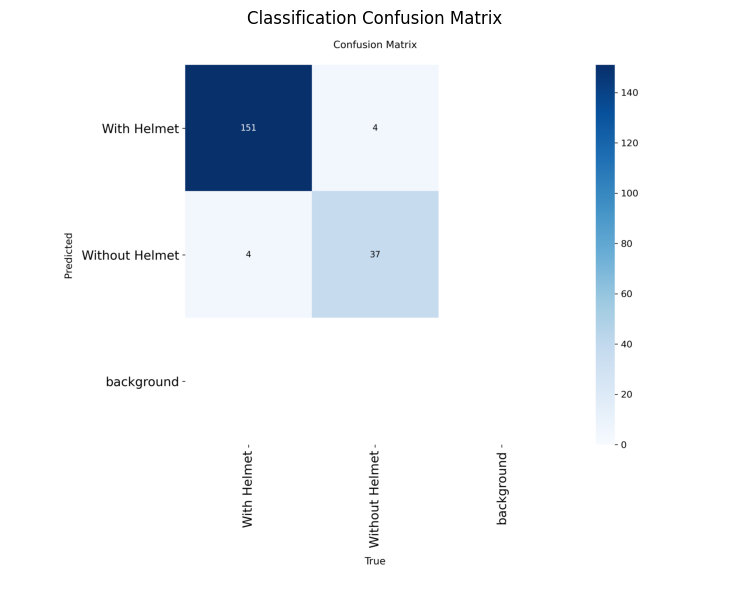

In [11]:
# YOLO saves confusion matrix automatically
cls_run_dir = WORK_DIR / "runs/cls_helmet"
cm_path = cls_run_dir / "confusion_matrix.png"

if cm_path.exists():
    img = mpimg.imread(str(cm_path))
    plt.figure(figsize=(8, 6))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Classification Confusion Matrix")
    plt.tight_layout()
    plt.savefig(str(WORK_DIR / "cls_confusion_matrix.png"), dpi=150)
    plt.show()
    
else:
    # Manually compute
    from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score
    test_cls_dir = WORK_DIR / "classification" / "test"
    y_true, y_pred = [], []
    label_map = {"helmet": 0, "no_helmet": 1}
    for cls_name, cls_id in label_map.items():
        for img_file in (test_cls_dir / cls_name).iterdir():
            result = cls_trained(str(img_file), verbose=False)[0]
            pred_id = result.probs.top1
            y_true.append(cls_id)
            y_pred.append(pred_id)
    acc = accuracy_score(y_true, y_pred)
    print(f"Manual Accuracy: {acc:.4f}")
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=["helmet", "no_helmet"])
    fig, ax = plt.subplots(figsize=(6, 5))
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    plt.title(f"Confusion Matrix (Acc={acc:.2f})")
    plt.tight_layout()
    plt.savefig(str(WORK_DIR / "cls_confusion_matrix.png"), dpi=150)
    plt.show()

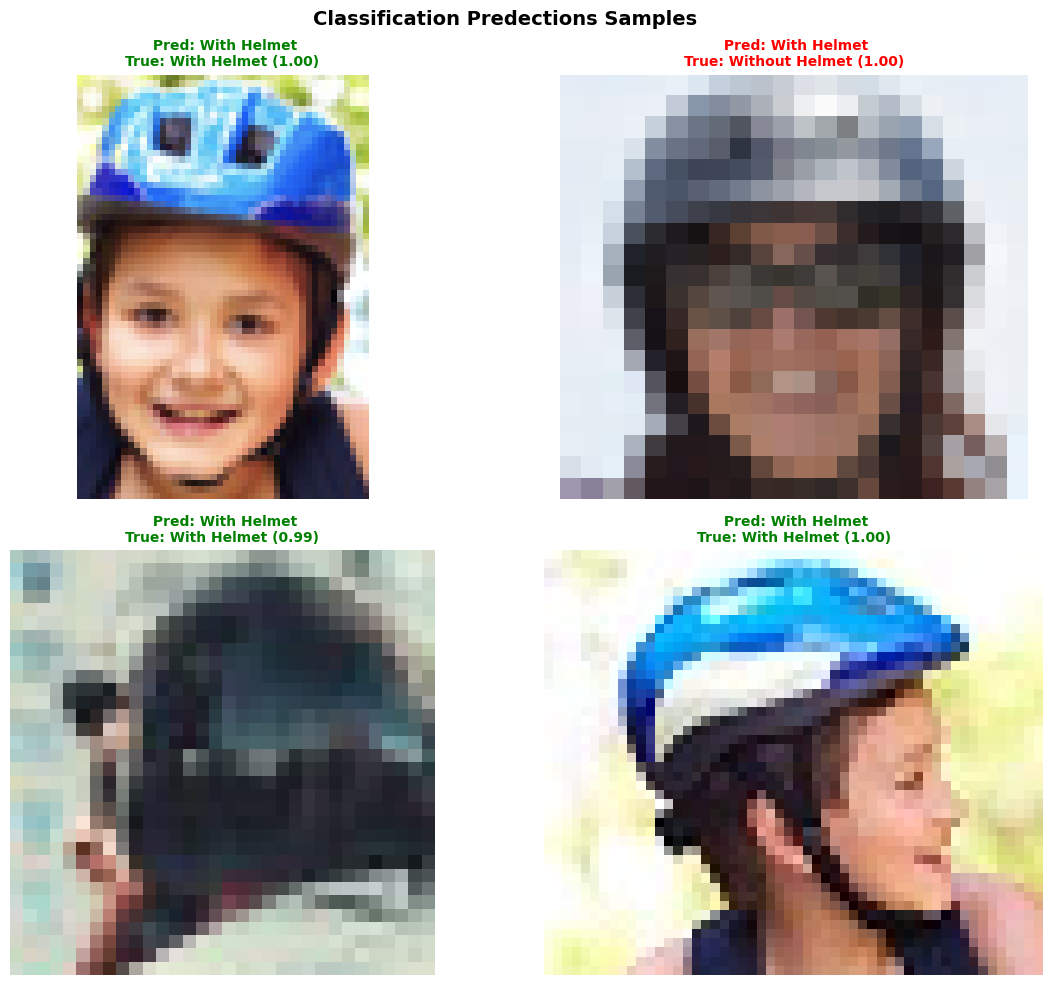

In [12]:
test_cls_dir = WORK_DIR / "classification" / "test"
CLASS_NAMES_CLS = ["With Helmet", "Without Helmet"]
COLORS = ["green", "red"]

all_samples = []
for cls_id, cls_name in enumerate(CLASS_NAMES_CLS):
    for img_file in (test_cls_dir / cls_name).iterdir():
        all_samples.append((img_file, cls_id))

random.shuffle(all_samples)
samples = all_samples[:4]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))  # grid 2x2
axes = axes.flatten()

for idx, (img_path, true_id) in enumerate(samples):
    result = cls_trained(str(img_path), verbose=False)[0]
    pred_id = result.probs.top1
    conf    = float(result.probs.top1conf)

    img = Image.open(img_path).convert("RGB")
    axes[idx].imshow(img)
    axes[idx].axis("off")

    true_label = CLASS_NAMES_CLS[true_id]
    pred_label = CLASS_NAMES_CLS[pred_id]
    is_correct = true_id == pred_id

    border_color = "green" if is_correct else "red"

    axes[idx].set_title(
        f" Pred: {pred_label}\nTrue: {true_label} ({conf:.2f})",
        fontsize=10, fontweight="bold", color=border_color
    )

    for spine in axes[idx].spines.values():
        spine.set_edgecolor(border_color)
        spine.set_linewidth(4)
        spine.set_visible(True)

plt.suptitle("Classification Predections Samples ", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(str(WORK_DIR / "classification_samples_4.png"), dpi=150)
plt.show()

## Step 7: Train Detection Model

Here, a YOLOv8 detection model is trained.

The model learns to:
- Detect helmets
- Draw bounding boxes
- Identify helmet locations

This model is used for object detection rather than classification.

In [13]:
det_model = YOLO("yolov8n.pt")

det_results = det_model.train(
    data=str(yaml_path),
    epochs=30,
    imgsz=640,
    batch=16,
    project=str(WORK_DIR / "runs"),
    name="det_helmet",
    exist_ok=True,
    verbose=False
)
print(" Detection training done!")

Ultralytics 8.4.15 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/helmet_project/helmet.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=det_helmet, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=

## Step 8: Evaluate Detection Model

The detection model is evaluated using standard object detection metrics:

- mAP
- Precision
- Recall

These metrics help measure how well the model detects helmets in images.

In [14]:
det_trained = YOLO(str(WORK_DIR / "runs/det_helmet/weights/best.pt"))

det_metrics = det_trained.val(
    data=str(yaml_path),
    split="test"
)

Ultralytics 8.4.15 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4000.9±1230.8 MB/s, size: 516.9 KB)
val: Scanning /kaggle/working/helmet_project/detection/test/labels... 115 images, 0 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 115/115 516.3it/s 0.2s
val: /kaggle/working/helmet_project/detection/test/images/BikesHelmets103.png: ignoring corrupt image/label: non-normalized or out of bounds coordinates [     408.72      81.502      71.037      83.004]
val: New cache created: /kaggle/working/helmet_project/detection/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.6it/s 2.2s
                   all        114        227      0.758      0.808      0.813      0.475
           With Helmet         84        152      0.811      0.821      0.862      0.562
        Withou

In [15]:
print("\n Detection Metrics:")
print(f"  mAP@0.5:      {det_metrics.box.map50:.4f}")
print(f"  mAP@0.5:0.95: {det_metrics.box.map:.4f}")
print(f"  Precision:    {det_metrics.box.mp:.4f}")
print(f"  Recall:       {det_metrics.box.mr:.4f}")


 Detection Metrics:
  mAP@0.5:      0.8133
  mAP@0.5:0.95: 0.4753
  Precision:    0.7579
  Recall:       0.8077


## Training Curves

Training curves are displayed to monitor model performance over time.

These graphs help show:
- Loss changes
- Model improvement
- Training stability

Available columns: ['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


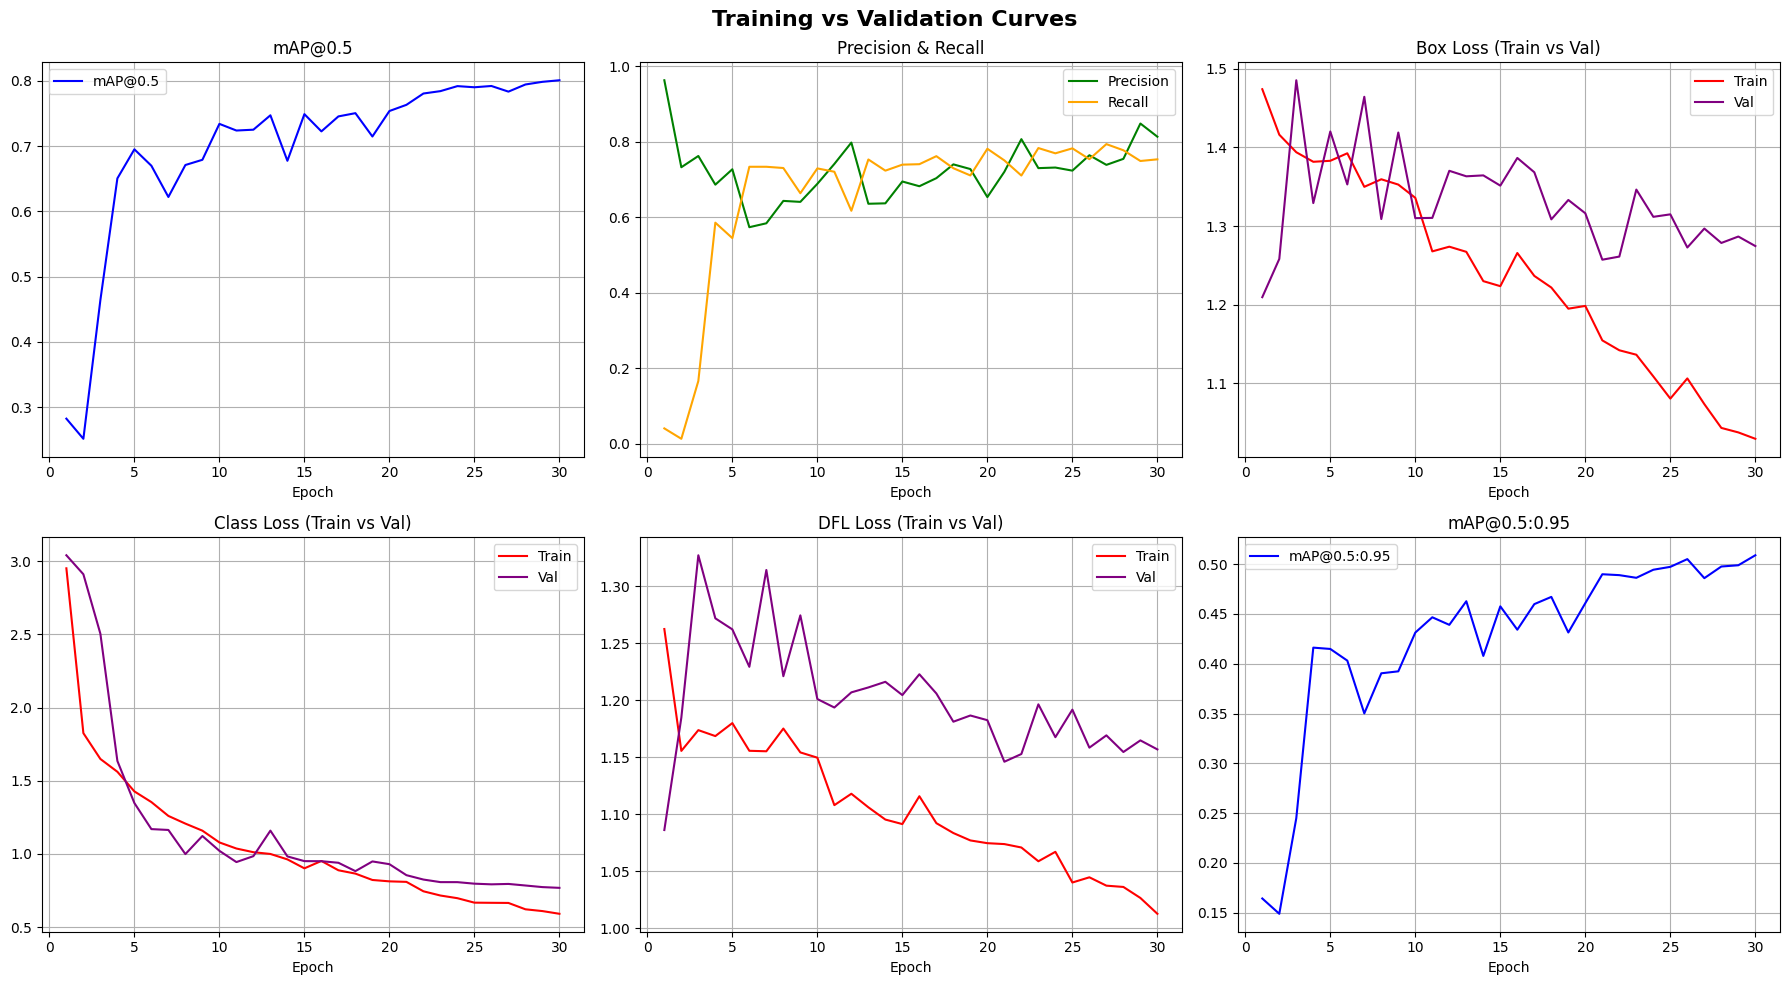

 Training curves saved!


In [16]:
# Training vs Validation Curves
results_csv = WORK_DIR / "runs/det_helmet/results.csv"
df = pd.read_csv(results_csv)
df.columns = df.columns.str.strip()

print("Available columns:", df.columns.tolist())

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# mAP
axes[0][0].plot(df["epoch"], df["metrics/mAP50(B)"], label="mAP@0.5", color="blue")
axes[0][0].set_title("mAP@0.5"); axes[0][0].set_xlabel("Epoch"); axes[0][0].legend(); axes[0][0].grid(True)

# Precision & Recall
axes[0][1].plot(df["epoch"], df["metrics/precision(B)"], label="Precision", color="green")
axes[0][1].plot(df["epoch"], df["metrics/recall(B)"], label="Recall", color="orange")
axes[0][1].set_title("Precision & Recall"); axes[0][1].set_xlabel("Epoch"); axes[0][1].legend(); axes[0][1].grid(True)

# Box Loss
axes[0][2].plot(df["epoch"], df["train/box_loss"], label="Train", color="red")
axes[0][2].plot(df["epoch"], df["val/box_loss"], label="Val", color="purple")
axes[0][2].set_title("Box Loss (Train vs Val)"); axes[0][2].set_xlabel("Epoch"); axes[0][2].legend(); axes[0][2].grid(True)

# Class Loss
axes[1][0].plot(df["epoch"], df["train/cls_loss"], label="Train", color="red")
axes[1][0].plot(df["epoch"], df["val/cls_loss"], label="Val", color="purple")
axes[1][0].set_title("Class Loss (Train vs Val)"); axes[1][0].set_xlabel("Epoch"); axes[1][0].legend(); axes[1][0].grid(True)

# DFL Loss
axes[1][1].plot(df["epoch"], df["train/dfl_loss"], label="Train", color="red")
axes[1][1].plot(df["epoch"], df["val/dfl_loss"], label="Val", color="purple")
axes[1][1].set_title("DFL Loss (Train vs Val)"); axes[1][1].set_xlabel("Epoch"); axes[1][1].legend(); axes[1][1].grid(True)

# mAP50-95
axes[1][2].plot(df["epoch"], df["metrics/mAP50-95(B)"], label="mAP@0.5:0.95", color="blue")
axes[1][2].set_title("mAP@0.5:0.95"); axes[1][2].set_xlabel("Epoch"); axes[1][2].legend(); axes[1][2].grid(True)

plt.suptitle("Training vs Validation Curves", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig(str(WORK_DIR / "training_curves.png"), dpi=150)
plt.show()
print(" Training curves saved!")

In [17]:
metrics_det = det_trained.val()
print(metrics_det)

Ultralytics 8.4.15 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 14913MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3477.3±1645.9 MB/s, size: 570.2 KB)
val: Scanning /kaggle/working/helmet_project/detection/val/labels.cache... 114 images, 0 backgrounds, 3 corrupt: 100% ━━━━━━━━━━━━ 114/114 47.8Mit/s 0.0s
val: /kaggle/working/helmet_project/detection/val/images/BikesHelmets326.png: ignoring corrupt image/label: non-normalized or out of bounds coordinates [        157        56.5          86          97]
val: /kaggle/working/helmet_project/detection/val/images/BikesHelmets530.png: ignoring corrupt image/label: non-normalized or out of bounds coordinates [     313.35          74      102.11         116]
val: /kaggle/working/helmet_project/detection/val/images/BikesHelmets764.png: ignoring corrupt image/label: non-normalized or out of bounds coordinates [        219          91          80          82]
                 Class     Images  Instances      Box(P          R      

## Step 9: Model Predictions

The trained model is tested on sample images.

This step shows:
- Detected objects
- Bounding boxes
- Predictions

It helps visually confirm that the model is working correctly.

In [18]:
det_trained.predict(
    source=str(WORK_DIR / "detection" / "test" / "images"),
    save=True,
    project=str(WORK_DIR / "runs"),
    name="predictions",
    exist_ok=True
)
print(" Predictions saved!")


image 1/115 /kaggle/working/helmet_project/detection/test/images/BikesHelmets103.png: 448x640 1 Without Helmet, 37.6ms
image 2/115 /kaggle/working/helmet_project/detection/test/images/BikesHelmets120.png: 384x640 1 With Helmet, 36.7ms
image 3/115 /kaggle/working/helmet_project/detection/test/images/BikesHelmets122.png: 480x640 1 With Helmet, 36.2ms
image 4/115 /kaggle/working/helmet_project/detection/test/images/BikesHelmets125.png: 480x640 2 With Helmets, 5.8ms
image 5/115 /kaggle/working/helmet_project/detection/test/images/BikesHelmets127.png: 640x416 1 With Helmet, 36.0ms
image 6/115 /kaggle/working/helmet_project/detection/test/images/BikesHelmets138.png: 448x640 1 With Helmet, 1 Without Helmet, 6.4ms
image 7/115 /kaggle/working/helmet_project/detection/test/images/BikesHelmets14.png: 384x640 1 With Helmet, 6.1ms
image 8/115 /kaggle/working/helmet_project/detection/test/images/BikesHelmets15.png: 448x640 1 With Helmet, 1 Without Helmet, 6.4ms
image 9/115 /kaggle/working/helmet_pr

/tmp/ipykernel_24/1574009912.py:50: UserWarning: Glyph 128309 (\N{LARGE BLUE CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/1574009912.py:50: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/1574009912.py:50: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/1574009912.py:51: UserWarning: Glyph 128309 (\N{LARGE BLUE CIRCLE}) missing from font(s) DejaVu Sans.
  plt.savefig(str(WORK_DIR / "inference_person_helmet.png"), dpi=150)
/tmp/ipykernel_24/1574009912.py:51: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) DejaVu Sans.
  plt.savefig(str(WORK_DIR / "inference_person_helmet.png"), dpi=150)
/tmp/ipykernel_24/1574009912.py:51: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.savefig(str(WORK_DIR / "inference_person_helmet.png"), dpi=150)
/usr/lo

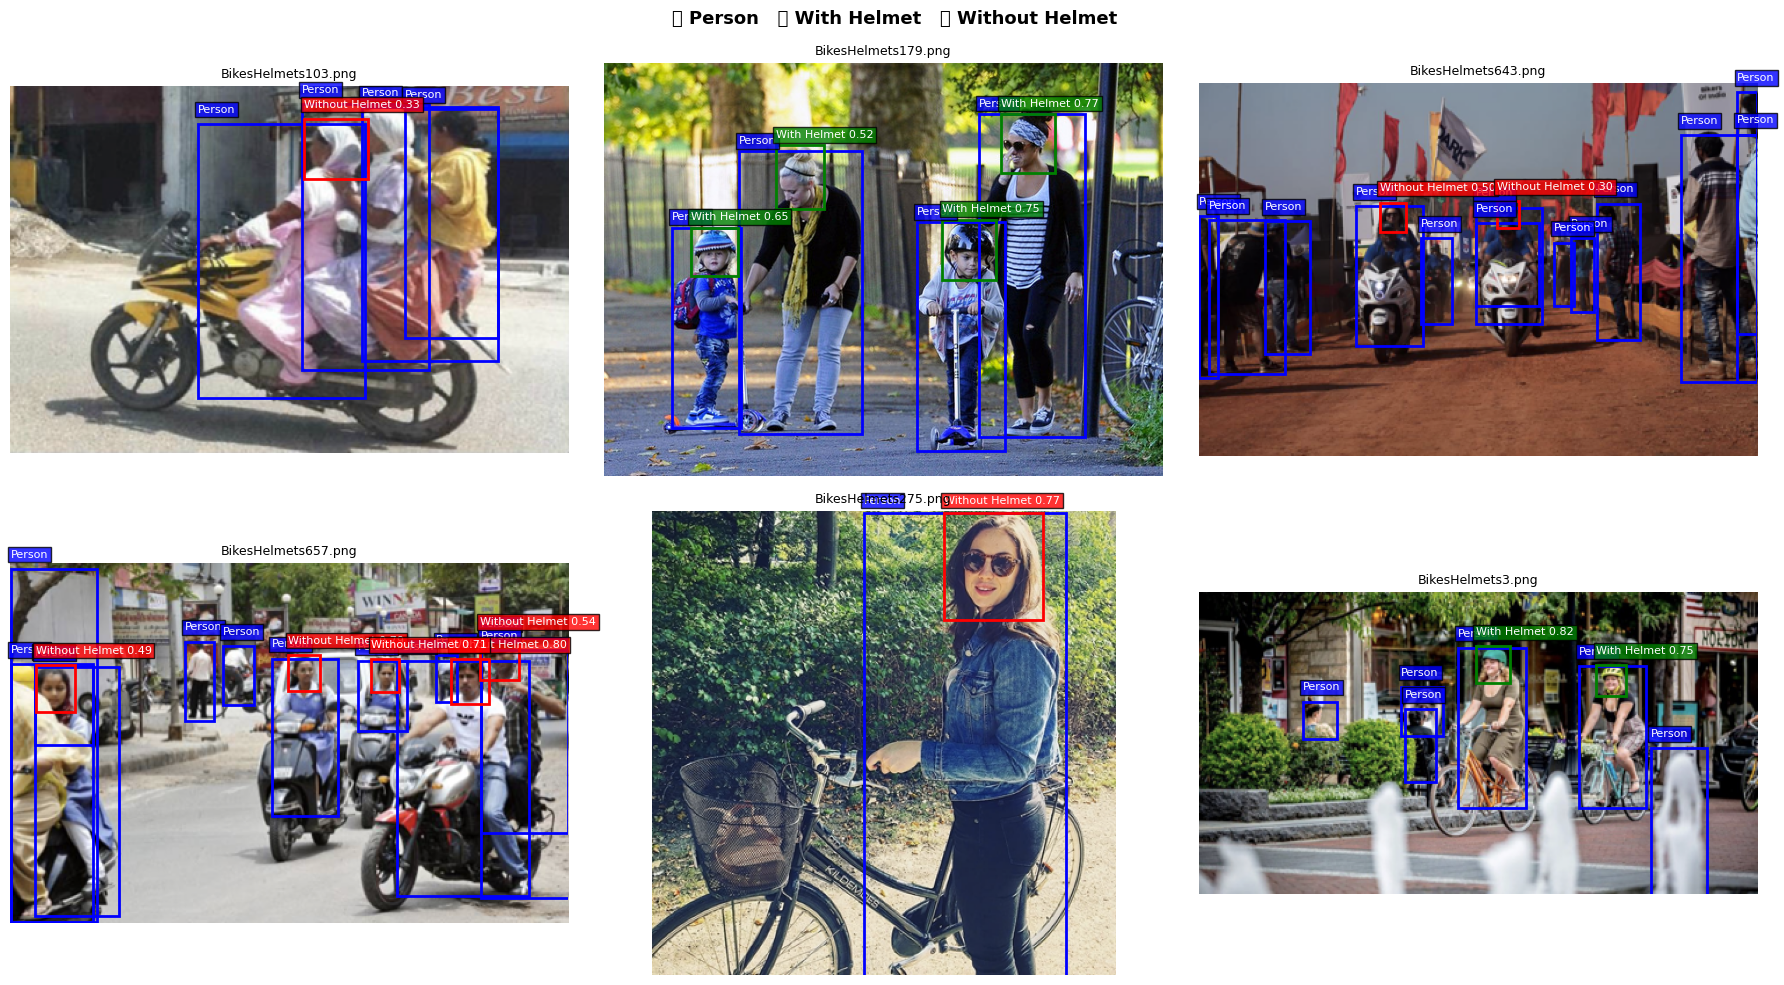

 Done!


In [19]:
person_model = YOLO("yolov8n.pt")  # pretrained على COCO يعرف person
helmet_model = YOLO(str(WORK_DIR / "runs/det_helmet/weights/best.pt"))

test_images = list((WORK_DIR / "detection" / "test" / "images").iterdir())[:6]
CLASS_NAMES = ["With Helmet", "Without Helmet"]
COLORS = {0: "green", 1: "red"}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, img_path in enumerate(test_images):
    img = Image.open(img_path).convert("RGB")
    ax = axes[idx]
    ax.imshow(img)

    # Step 1: detect persons
    person_results = person_model(str(img_path), conf=0.3, classes=[0], verbose=False)[0]

    # Step 2: detect helmets
    helmet_results = helmet_model(str(img_path), conf=0.3, verbose=False)[0]

    # ارسم الـ person boxes باللون الأزرق
    if person_results.boxes is not None:
        for box in person_results.boxes:
            x1, y1, x2, y2 = box.xyxy[0].tolist()
            rect = patches.Rectangle((x1, y1), x2-x1, y2-y1,
                                      linewidth=2, edgecolor="blue", facecolor="none")
            ax.add_patch(rect)
            ax.text(x1, y1-8, "Person", color="white", fontsize=8,
                    bbox=dict(facecolor="blue", alpha=0.8, pad=2))

    # ارسم الـ helmet boxes
    if helmet_results.boxes is not None:
        for box in helmet_results.boxes:
            x1, y1, x2, y2 = box.xyxy[0].tolist()
            cls_id = int(box.cls[0])
            conf   = float(box.conf[0])
            color  = COLORS[cls_id]
            label  = f"{CLASS_NAMES[cls_id]} {conf:.2f}"
            rect = patches.Rectangle((x1, y1), x2-x1, y2-y1,
                                      linewidth=2, edgecolor=color, facecolor="none")
            ax.add_patch(rect)
            ax.text(x1, y1-8, label, color="white", fontsize=8,
                    bbox=dict(facecolor=color, alpha=0.8, pad=2))

    ax.axis("off")
    ax.set_title(img_path.name[:25], fontsize=9)

plt.suptitle("🔵 Person   🟢 With Helmet   🔴 Without Helmet", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(str(WORK_DIR / "inference_person_helmet.png"), dpi=150)
plt.show()
print(" Done!")

## Step 10: Final Results

Final performance of the models:

In [20]:
print("=" * 55)
print("       HELMET DETECTION PROJECT — FINAL REPORT")
print("=" * 55)

print("\n Dataset:")
for split in ["train", "val", "test"]:
    n = len(list((WORK_DIR / "detection" / split / "images").iterdir()))
    print(f"   {split:5s}: {n} images")

print("\n Classification (YOLOv8n-cls):")
print(f"   Top-1 Accuracy: {val_metrics.top1:.4f}")

print("\n Detection (YOLOv8n):")
print(f"   mAP@0.5:       {det_metrics.box.map50:.4f}")
print(f"   mAP@0.5:0.95:  {det_metrics.box.map:.4f}")
print(f"   Precision:     {det_metrics.box.mp:.4f}")
print(f"   Recall:        {det_metrics.box.mr:.4f}")

print("\n Output Files:")
print(f"   {WORK_DIR}/runs/cls_helmet/weights/best.pt  ← Classification model")
print(f"   {WORK_DIR}/runs/det_helmet/weights/best.pt  ← Detection model")
print(f"   {WORK_DIR}/inference_results.png            ← Sample predictions")
print(f"   {WORK_DIR}/detection_curves.png             ← Training curves")
print("=" * 55)

       HELMET DETECTION PROJECT — FINAL REPORT

 Dataset:
   train: 532 images
   val  : 114 images
   test : 115 images

 Classification (YOLOv8n-cls):
   Top-1 Accuracy: 0.9339

 Detection (YOLOv8n):
   mAP@0.5:       0.8133
   mAP@0.5:0.95:  0.4753
   Precision:     0.7579
   Recall:        0.8077

 Output Files:
   /kaggle/working/helmet_project/runs/cls_helmet/weights/best.pt  ← Classification model
   /kaggle/working/helmet_project/runs/det_helmet/weights/best.pt  ← Detection model
   /kaggle/working/helmet_project/inference_results.png            ← Sample predictions
   /kaggle/working/helmet_project/detection_curves.png             ← Training curves
